<a href="https://colab.research.google.com/github/Athul-11/apexplanet-task-1/blob/main/AIML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Data/top100cities_weather_data.csv')

df.head()

,City,Temperature (Celsius),Wind Speed (m/s),Latitude,Longitude,Description,Country
0,Paris,10.46,2.06,48.8534,2.3488,clear sky,France
1,Dubai,29.32,3.09,25.2582,55.3047,clear sky,United Arab Emirates
2,Madrid,9.97,3.60,40.4165,-3.7026,clear sky,Spain
3,Tokyo,21.58,2.06,35.6895,139.6917,broken clouds,Japan
4,Amsterdam,8.00,3.58,52.3740,4.8897,clear sky,Netherlands


The weather dataset was loaded into Google Colab using the Pandas library. The first few rows and dataset information were displayed to understand its structure.

In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   City                   100 non-null    object 
 1   Temperature (Celsius)  100 non-null    float64
 2   Wind Speed (m/s)       100 non-null    float64
 3   Latitude               100 non-null    float64
 4   Longitude              100 non-null    float64
 5   Description            100 non-null    object 
 6   Country                100 non-null    object 
dtypes: float64(4), object(3)
memory usage: 5.6+ KB


,Temperature (Celsius),Wind Speed (m/s),Latitude,Longitude
count,100.000000,100.00000,100.000000,100.000000
mean,18.861700,3.59920,31.249418,18.550782
std,7.017078,2.66491,19.451234,75.876596
min,5.290000,0.45000,-34.613200,-157.858300
25%,13.825000,1.54000,23.489600,-8.741575
50%,18.005000,2.92500,35.173650,18.552400
75%,26.120000,4.63000,43.825025,74.154525
max,32.350000,14.75000,59.437000,151.207300


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.dtypes)


Rows: 100
Columns: 7
City                      object
Temperature (Celsius)    float64
Wind Speed (m/s)         float64
Latitude                 float64
Longitude                float64
Description               object
Country                   object
dtype: object


In [ ]:
df.tail()

,City,Temperature (Celsius),Wind Speed (m/s),Latitude,Longitude,Description,Country
95,Punta Cana,26.87,6.69,18.5818,-68.4043,few clouds,Dominican Republic
96,Guilin,24.06,0.97,25.2819,110.2864,clear sky,China
97,Hanoi,28.00,2.49,21.0245,105.8412,clear sky,Vietnam
98,Cairo,19.42,4.63,30.0626,31.2497,clear sky,Egypt
99,Muscat,28.01,2.76,23.6139,58.5922,broken clouds,Oman


In [ ]:
df.sample(5)

,City,Temperature (Celsius),Wind Speed (m/s),Latitude,Longitude,Description,Country
20,Prague,14.12,1.54,50.0880,14.4208,clear sky,Czech Republic
72,Sharjah,27.16,3.09,25.3573,55.4033,clear sky,United Arab Emirates
53,São Paulo,23.91,4.12,-23.5475,-46.6361,clear sky,Brazil
56,Antalya,18.94,2.57,36.7741,30.7178,clear sky,Turkey
27,Taipei,24.10,1.54,25.0478,121.5319,scattered clouds,Taiwan


The first, last, and random records of the dataset were displayed to inspect the data

In [ ]:
print(df.isnull().sum())
df.dropna(inplace=True)

City                     0
Temperature (Celsius)    0
Wind Speed (m/s)         0
Latitude                 0
Longitude                0
Description              0
Country                  0
dtype: int64


Missing values were identified and handled using appropriate techniques.

In [ ]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

Duplicate records were identified and removed.

In [ ]:
Q1 = df["Latitude"].quantile(0.25)
Q3 = df["Latitude"].quantile(0.75)

IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df["Latitude"] < lower) | (df["Latitude"] > upper)]

outliers
print("Number of outliers:", len(outliers))

Number of outliers: 6


Outliers were detected using the IQR method and visualized using a box plot.

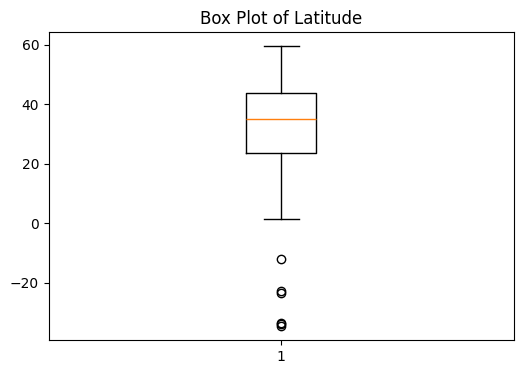

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.boxplot(df["Latitude"])
plt.title("Box Plot of Latitude")
plt.show()

Detected outliers were handled using clipping.

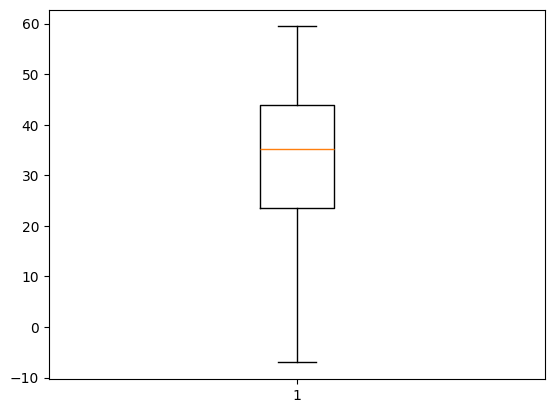

In [ ]:
df["Latitude"] = df["Latitude"].clip(lower, upper)
plt.boxplot(df["Latitude"])
plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
minmax = MinMaxScaler()
df[["Latitude"]] = minmax.fit_transform(df[["Latitude"]])
standard = StandardScaler()
df[["Latitude"]] = standard.fit_transform(df[["Latitude"]])

Feature scaling was performed using Min-Max Normalization and Standardization.

In [ ]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()
corr

,Temperature (Celsius),Wind Speed (m/s),Latitude,Longitude
Temperature (Celsius),1.000000,0.084105,-0.684449,0.078445
Wind Speed (m/s),0.084105,1.000000,-0.080801,-0.559044
Latitude,-0.684449,-0.080801,1.000000,-0.107855
Longitude,0.078445,-0.559044,-0.107855,1.000000


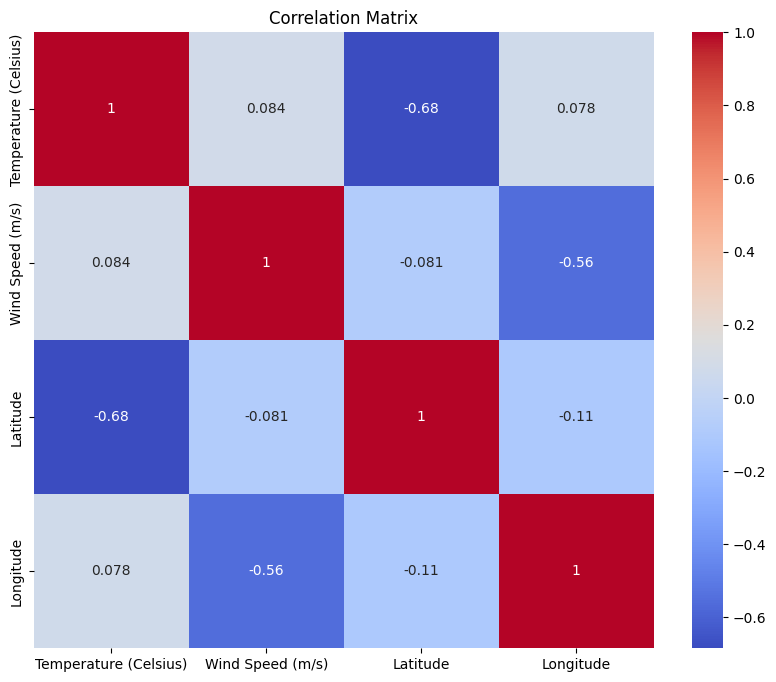

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10,8))
sns.heatmap(corr,
            annot=True,
            cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

A correlation matrix and heatmap were generated to visualize feature relationships.

In [ ]:
df.dtypes
df["Temperature (Celsius)"] = df["Temperature (Celsius)"].astype(int)
display(df)

,City,Temperature (Celsius),Wind Speed (m/s),Latitude,Longitude,Description,Country
0,Paris,10,2.06,1.027757,2.3488,clear sky,France
1,Dubai,29,3.09,-0.449065,55.3047,clear sky,United Arab Emirates
2,Madrid,9,3.60,0.499692,-3.7026,clear sky,Spain
3,Tokyo,21,2.06,0.203829,139.6917,broken clouds,Japan
4,Amsterdam,8,3.58,1.248111,4.8897,clear sky,Netherlands
...,...,...,...,...,...,...,...
95,Punta Cana,26,6.69,-0.866941,-68.4043,few clouds,Dominican Republic
96,Guilin,24,0.97,-0.447582,110.2864,clear sky,China
97,Hanoi,28,2.49,-0.714052,105.8412,clear sky,Vietnam
98,Cairo,19,4.63,-0.148358,31.2497,clear sky,Egypt


Data types were checked and converted where necessary.

In [ ]:
df["City"] = df["City"].str.strip()
df["Country"] = df["Country"].str.strip()
df["Description"] = df["Description"].str.strip()

df["City"] = df["City"].str.lower()
df["Country"] = df["Country"].str.lower()
df["Description"] = df["Description"].str.lower()

df["City"] = df["City"].str.replace(r"\s+", " ", regex=True)
df.head()

,City,Temperature (Celsius),Wind Speed (m/s),Latitude,Longitude,Description,Country
0,paris,10,2.06,1.027757,2.3488,clear sky,france
1,dubai,29,3.09,-0.449065,55.3047,clear sky,united arab emirates
2,madrid,9,3.60,0.499692,-3.7026,clear sky,spain
3,tokyo,21,2.06,0.203829,139.6917,broken clouds,japan
4,amsterdam,8,3.58,1.248111,4.8897,clear sky,netherlands


Inconsistent and noisy data were cleaned by standardizing text values.

In [ ]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Training Set:", train_data.shape)
print("Testing Set:", test_data.shape)

Training Set: (80, 7)
Testing Set: (20, 7)


The dataset was split into training and testing sets.

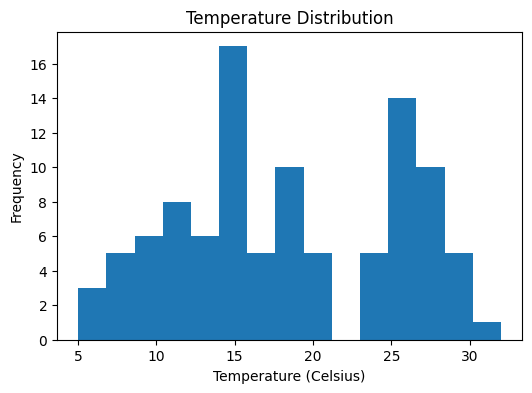

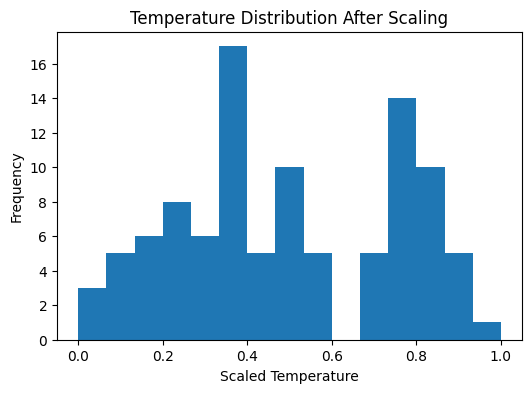

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.hist(df["Temperature (Celsius)"], bins=15)
plt.title("Temperature Distribution")
plt.xlabel("Temperature (Celsius)")
plt.ylabel("Frequency")
plt.show()

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaled_temp = scaler.fit_transform(df[["Temperature (Celsius)"]])
plt.figure(figsize=(6,4))
plt.hist(scaled_temp, bins=15)
plt.title("Temperature Distribution After Scaling")
plt.xlabel("Scaled Temperature")
plt.ylabel("Frequency")
plt.show()

The distribution of numerical features before and after preprocessing was visualized.

In [ ]:
df.to_csv("top100cities_weather_data_cleaned.csv", index=False)
from google.colab import files
files.download("top100cities_weather_data_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The cleaned dataset was saved as a new CSV file.

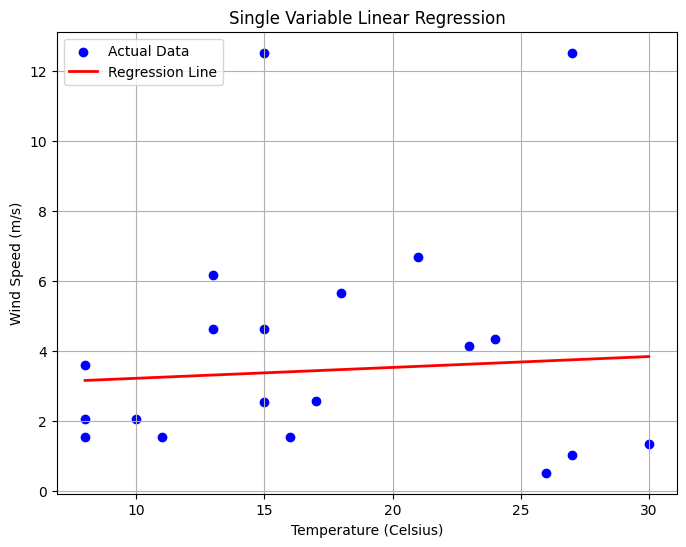


Actual vs Predicted:
   Actual Wind Speed  Predicted Wind Speed
0               1.33              3.831870
1               4.12              3.614387
2               2.53              3.365835
3               6.17              3.303697
4               4.32              3.645456

Model Evaluation
MAE: 2.3925189276277226
MSE: 11.238203073074379
RMSE: 3.3523429229531962


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train = train_data[['Temperature (Celsius)']]
y_train = train_data['Wind Speed (m/s)']

X_test = test_data[['Temperature (Celsius)']]
y_test = test_data['Wind Speed (m/s)']

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

sorted_index = np.argsort(X_test.values.flatten())

X_sorted = X_test.values.flatten()[sorted_index]
y_sorted = y_pred[sorted_index]

plt.figure(figsize=(8,6))

plt.scatter(X_test,
            y_test,
            color='blue',
            label='Actual Data')

plt.plot(X_sorted,
         y_sorted,
         color='red',
         linewidth=2,
         label='Regression Line')


plt.title("Single Variable Linear Regression")
plt.xlabel("Temperature (Celsius)")
plt.ylabel("Wind Speed (m/s)")

plt.legend()
plt.grid(True)

plt.show()



comparison = pd.DataFrame({
    "Actual Wind Speed": y_test.values,
    "Predicted Wind Speed": y_pred
})

print("\nActual vs Predicted:")
print(comparison.head())


print("\nModel Evaluation")

print("MAE:",
      mean_absolute_error(y_test, y_pred))

print("MSE:",
      mean_squared_error(y_test, y_pred))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred)))



Linear regression using y=mx+c done

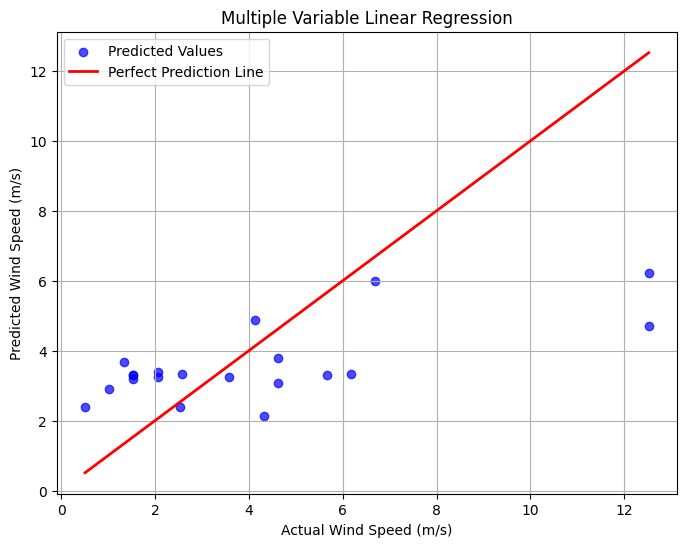


Actual vs Predicted:
   Actual Wind Speed  Predicted Wind Speed
0               1.33              3.680890
1               4.12              4.865151
2               2.53              2.398202
3               6.17              3.343783
4               4.32              2.128263

Model Evaluation
MAE: 2.018303635058544
MSE: 7.441607127957465
RMSE: 2.7279309243376133


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


X_train = train_data.drop("Wind Speed (m/s)", axis=1)
y_train = train_data["Wind Speed (m/s)"]

X_test = test_data.drop("Wind Speed (m/s)", axis=1)
y_test = test_data["Wind Speed (m/s)"]


X_train = X_train.select_dtypes(include=['int64', 'float64'])
X_test = X_test.select_dtypes(include=['int64', 'float64'])

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

plt.figure(figsize=(8,6))

plt.scatter(y_test,
            y_pred,
            color='blue',
            alpha=0.7,
            label="Predicted Values")


plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red',
         linewidth=2,
         label="Perfect Prediction Line")


plt.title("Multiple Variable Linear Regression")
plt.xlabel("Actual Wind Speed (m/s)")
plt.ylabel("Predicted Wind Speed (m/s)")

plt.legend()
plt.grid(True)

plt.show()


comparison = pd.DataFrame({
    "Actual Wind Speed": y_test.values,
    "Predicted Wind Speed": y_pred
})

print("\nActual vs Predicted:")
print(comparison.head())

print("\nModel Evaluation")
print("MAE:",
      mean_absolute_error(y_test, y_pred))
print("MSE:",
      mean_squared_error(y_test, y_pred))
print("RMSE:",
      mean_squared_error(y_test, y_pred) ** 0.5)



In [ ]:
#UCS
import heapq
def uniform_cost_search(graph, start, goal):
    queue = [(0, start, [start])]
    visited = set()
    while queue:
        cost, node, path = heapq.heappop(queue)
        if node in visited:
            continue
        visited.add(node)
        if node == goal:
            return cost, path
        for neighbor, edge_cost in graph[node]:
            if neighbor not in visited:
                heapq.heappush(
                    queue,
                    (cost + edge_cost, neighbor, path + [neighbor])
                )
    return float("inf"), []
graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('C', 2), ('D', 5)],
    'C': [('D', 1)],
    'D': []
}
cost, path = uniform_cost_search(graph, 'A', 'D')
print("Minimum cost:", cost)
print("Path:",path)

Minimum cost: 4
Path: ['A', 'B', 'C', 'D']


**DFS AND BFS**

In [ ]:
#DFS
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['F'],
    'F': []
}

visited = set()

def dfs(node):
    if node not in visited:
        print(node, end=" ")
        visited.add(node)
        for neighbor in graph[node]:
            dfs(neighbor)
dfs('A')

A B D E F C 

In [ ]:
#BFS
from collections import deque

graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['F'],
    'F': []
}

visited = set()
queue = deque()

def bfs(start):
    visited.add(start)
    queue.append(start)

    while queue:
        node = queue.popleft()
        print(node, end=" ")

        for neighbor in graph[node]:
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)

bfs('A')

A B C D E F 

In [ ]:
# A* algorithm
import heapq
def a_star(graph, heuristic, start, goal):
    pq = [(heuristic[start], start)]
    g_cost = {start: 0}
    parent = {start: None}
    while pq:
        f, current = heapq.heappop(pq)
        if current == goal:
            path = []
            while current is not None:
                path.append(current)
                current = parent[current]
            path.reverse()
            return path, g_cost[goal]
        for neighbor, cost in graph[current]:
            new_g = g_cost[current] + cost
            if neighbor not in g_cost or new_g < g_cost[neighbor]:
                g_cost[neighbor] = new_g
                f = new_g + heuristic[neighbor]
                parent[neighbor] = current
                heapq.heappush(pq, (f, neighbor))
    return None, float('inf')
graph = {
    'A': [('B', 2), ('C', 4)],
    'B': [('A', 2), ('C', 1), ('D', 7)],
    'C': [('A', 4), ('B', 1), ('D', 3), ('E', 5)],
    'D': [('B', 7), ('C', 3), ('E', 2), ('F', 4)],
    'E': [('C', 5), ('D', 2), ('F', 1)],
    'F': [('D', 4), ('E', 1)]
}
heuristic = {
    'A': 10,
    'B': 8,
    'C': 7,
    'D': 5,
    'E': 3,
    'F': 0
}
path, cost = a_star(graph, heuristic, 'A', 'F')
print("Path:", path)
print("Cost:", cost)

Path: ['A', 'B', 'C', 'D', 'F']
Cost: 10


In [ ]:
#Greedy best first search
def greedy_search(graph, heuristic, start, goal):
    visited = set()
    queue = [(heuristic[start], start)]

    while queue:
        queue.sort()
        _, current = queue.pop(0)

        if current in visited:
            continue

        print("Visiting:", current)
        visited.add(current)

        if current == goal:
            return True

        for neighbor in graph[current]:
            if neighbor not in visited:
                queue.append((heuristic[neighbor], neighbor))

    return False

graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['G'],
    'F': ['G'],
    'G': []
}

heuristic = {
    'A': 6,
    'B': 4,
    'C': 5,
    'D': 7,
    'E': 2,
    'F': 3,
    'G': 0
}

result = greedy_search(graph, heuristic, 'A', 'G')

print("Goal reached:",result)


Visiting: A
Visiting: B
Visiting: E
Visiting: G
Goal reached: True


In [ ]:
#Decision Tree Regression
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

data = load_diabetes()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = DecisionTreeRegressor(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))



Mean Squared Error: 4976.797752808989
R2 Score: 0.060653981041140725


In [ ]:
#Support Vector Machine Regression

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

data = load_diabetes()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SVR()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Squared Error: 4332.738479345717
R2 Score: 0.18221699094239507


In [ ]:
#Random Forest Regression

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

data = load_diabetes()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))


Mean Squared Error: 2952.0105887640448
R2 Score: 0.4428225673999313


In [ ]:
#Decision Tree Classifier

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

data = load_iris()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 1.0


In [ ]:
#Support Vector Machine Classifier

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

data = load_iris()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SVC()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 1.0


In [ ]:
#Random Forest Classifier

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

data = load_iris()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


In [ ]:
#Simple Ensemble Regressor
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.metrics import mean_squared_error, r2_score

data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2, random_state=42)

m1 = DecisionTreeRegressor(random_state=42)
m2 = make_pipeline(StandardScaler(), SVR())
m3 = RandomForestRegressor(n_estimators=100, random_state=42)


ensemble = VotingRegressor(
    estimators=[('dt', m1), ('svm', m2), ('rf', m3)]
)


ensemble.fit(X_train, y_train)
y_pred = ensemble.predict(X_test)

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Squared Error: 3125.3230615816415
R2 Score: 0.41011069332684125


In [ ]:
#Simple Ensemble Classifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score

data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2, random_state=42)

m1 = DecisionTreeClassifier(random_state=42)
m2 = make_pipeline(StandardScaler(), SVC())
m3 = RandomForestClassifier(n_estimators=100, random_state=42)

ensemble = VotingClassifier(
    estimators=[('dt', m1), ('svm', m2), ('rf', m3)]
)

ensemble.fit(X_train, y_train)
y_pred = ensemble.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0
